# Inventory Risk and Profit Optimization Using Monte Carlo Simulation

## 1. Problem Statement
Retail businesses often face uncertainty in daily customer demand. Purchasing too much inventory can lead to excess stock and unnecessary costs, while purchasing too little can result in stockouts, lost sales, and reduced customer satisfaction.

This project aims to develop a data-driven inventory decision-support model using Monte Carlo simulation. The model will evaluate different inventory levels, estimate stockout probabilities, analyze expected profits, and identify inventory decisions that balance profitability and business risk.


## 2. Project Objectives

The main objectives of this project are:

1. **Analyze Customer Demand:** Explore and clean inventory and demand data to understand historical demand patterns.

2. **Simulate Future Demand:** Use Monte Carlo simulation to generate possible future demand scenarios under uncertainty.

3. **Evaluate Inventory Risk:** Calculate stockout probability, expected shortages, and the risk of excess inventory.

4. **Analyze Profitability:** Estimate expected revenue, inventory costs, and profit for different stock levels.

5. **Optimize Inventory Decisions:** Identify inventory levels that maximize expected profit while satisfying business risk constraints.

6. **Evaluate Model Reliability:** Use bootstrap confidence intervals and sensitivity analysis to assess uncertainty and the impact of model assumptions.

7. **Communicate Results:** Present findings through visualizations, clear business recommendations, and reproducible project documentation.


## 3. Dataset Design

### Dataset Overview

This project will initially use a synthetic dataset representing the daily customer demand for a single retail product.

The dataset will be used to explore demand patterns, estimate demand variability, and support Monte Carlo simulations of future demand.

### Dataset Structure

| Column | Data Type | Description |
|---|---|---|
| date | Date | Date of the observation |
| demand_units | Integer | Number of product units demanded on that day |

### Data Source

The initial dataset will be synthetically generated using Python. This allows us to develop and validate the inventory simulation model before applying it to real business data.

### Planned Analysis

- Explore daily customer demand patterns.
- Calculate descriptive statistics.
- Identify unusual observations and data-quality issues.
- Estimate a suitable demand distribution.
- Use the estimated demand model for inventory simulations.


## 4. Synthetic Demand Data Generation

### 4.1 Modeling Assumptions

Since historical customer demand data is not available, this project uses synthetically generated daily demand data.

The dataset covers 90 days, with customer demand modeled using a Normal distribution with an assumed mean of 75 units per day and a standard deviation of 12 units.

These values are modeling assumptions rather than estimates derived from real business data. Therefore, the simulated demand may not accurately represent the actual demand patterns of a real retailer.

### 4.2 Generating Raw Demand

In [1]:
import numpy as np
rng = np.random.default_rng(42)
daily_demand = rng.normal(loc=75, scale=12, size=90)
print(daily_demand[:5])

[78.65660496 62.52019073 84.00541435 86.2867766  51.58757774]


Daily customer demand is not constant and may fluctuate from one day to another. To represent this uncertainty, synthetic demand observations are generated using a Normal distribution with an assumed mean of 75 units and a standard deviation of 12 units. This provides an initial approximation of demand variability rather than a verified model of actual retail demand.

### 4.3 Data Cleaning and Validation

In [2]:
rounded_demand = np.rint(daily_demand)
print(rounded_demand[:5])

[79. 63. 84. 86. 52.]


In [3]:
print(np.min(rounded_demand))

52.0


In [4]:
cleaned_demand = np.maximum(rounded_demand, 0)
np.min(cleaned_demand)

np.float64(52.0)

In [5]:
final_demand = cleaned_demand.astype(int)
print(final_demand[:5])

[79 63 84 86 52]


In [6]:
print(final_demand.dtype)

int64


**Data Cleaning Interpretation**

The generated demand values were rounded to the nearest whole number because customer demand is measured in individual product units.

A non-negativity safeguard was applied using np.maximum() to prevent negative demand values. No negative values were present in the generated dataset.

Finally, the cleaned demand values were converted to integers using `.astype(int)`, making the dataset suitable for inventory analysis.

### 4.4 Creating Dates and DataFrame

In [7]:
import pandas as pd
dates = pd.date_range(start="2026-01-01", periods=90, freq="D")
print(dates[:5])

DatetimeIndex(['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04',
               '2026-01-05'],
              dtype='datetime64[us]', freq='D')


In [8]:
df = pd.DataFrame({
    "date" : dates,
    "demand_units" : final_demand
})
df.head()


,date,demand_units
0,2026-01-01,79
1,2026-01-02,63
2,2026-01-03,84
3,2026-01-04,86
4,2026-01-05,52


In [9]:
df.shape

(90, 2)

In [10]:
df.isna().sum()

date            0
demand_units    0
dtype: int64

In [11]:
df.dtypes

date            datetime64[us]
demand_units             int64
dtype: object

In [12]:
min_daily_demand = df["demand_units"].min()
print(min_daily_demand)

52


In [13]:
df["date"].is_unique

True

In [14]:
date_gaps = df["date"].diff()
date_gaps.head()

0      NaT
1   1 days
2   1 days
3   1 days
4   1 days
Name: date, dtype: timedelta64[us]

In [15]:
date_gaps.dropna().unique()

<TimedeltaArray>
['1 days']
Length: 1, dtype: timedelta64[us]

DataFrame Construction and Validation — Interpretation

The synthetic dataset contains 90 daily observations and two columns: date and demand_units.

Data validation confirmed that both columns contain no missing values and have appropriate data types. The minimum observed customer demand is 52 units, indicating that no negative demand values are present.

All dates are unique and consecutive, with a one-day interval between observations. These checks confirm that the generated dataset satisfies the basic structural requirements for the next stage of analysis.

### 4.5 Exporting the Validated Dataset

In [16]:
df.to_csv("synthetic_daily_demand.csv", index=False)

In [17]:
exported_demand_df = pd.read_csv("synthetic_daily_demand.csv", parse_dates=["date"])

In [18]:
exported_demand_df.head()

,date,demand_units
0,2026-01-01,79
1,2026-01-02,63
2,2026-01-03,84
3,2026-01-04,86
4,2026-01-05,52


In [19]:
exported_demand_df.shape

(90, 2)

In [20]:
df.equals(exported_demand_df)

True

**CSV Export Validation — Interpretation**

The validated synthetic demand dataset was exported to a CSV file without including the DataFrame index.

The exported file was successfully reloaded using Pandas. The imported dataset contains 90 rows and 2 columns.

A complete DataFrame equality check returned `True`, confirming that the imported dataset matches the original DataFrame.

## 5. Exploratory Data Analysis (EDA)

### 5.1 Descriptive Statistics

In [21]:
df["demand_units"].describe()

count     90.000000
mean      75.166667
std        9.075526
min       52.000000
25%       69.000000
50%       76.000000
75%       82.000000
max      101.000000
Name: demand_units, dtype: float64

**Descriptive Statistics — Interpretation**

The dataset contains 90 daily demand observations, with an average demand of approximately 75.17 units and a median of 76 units.

Daily demand ranges from 52 to 101 units, with an observed standard deviation of approximately 9.08 units, indicating variability in customer demand.

The middle 50% of observations lie between 69 and 82 units. These results describe the generated dataset under the assumed demand model.

### 5.2 Demand Distribution — Histogram

In [22]:
import matplotlib.pyplot as plt

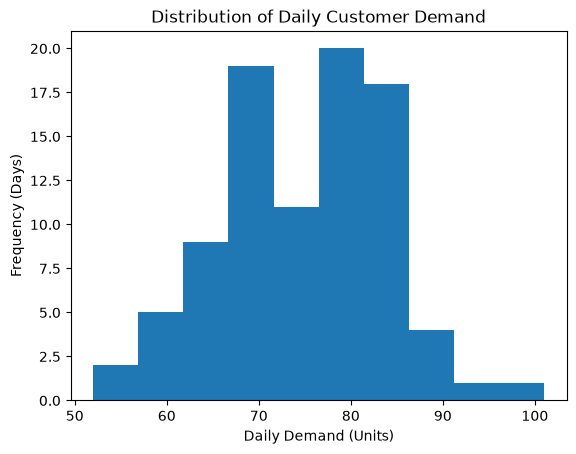

In [23]:
plt.hist(df["demand_units"], bins=10)
plt.xlabel("Daily Demand (Units)")
plt.ylabel("Frequency (Days)")
plt.title("Distribution of Daily Customer Demand")
plt.show()

**Demand Distribution — Interpretation**

The histogram indicates that daily customer demand is primarily concentrated between approximately 65 and 85 units, with fewer observations at the lower and upper extremes.

The distribution is broadly concentrated around the observed mean of 75.17 units. However, the histogram alone does not establish that the data follows a Normal distribution.

These findings highlight variability in daily demand. Therefore, inventory decisions should consider both demand uncertainty and business costs rather than relying only on the most frequently observed demand range.

### 5.3 Daily Demand Trend Visualization

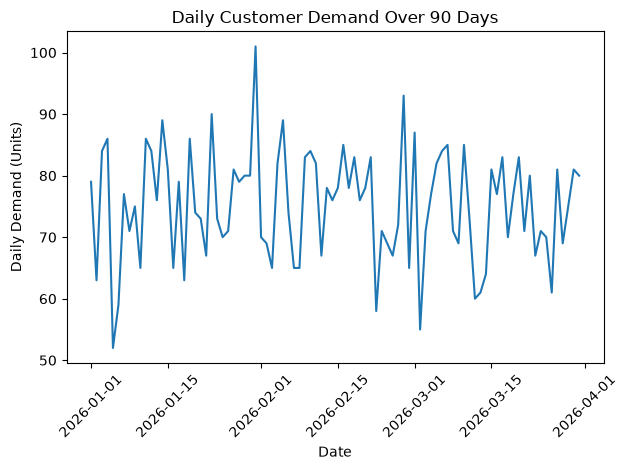

In [24]:
plt.plot(df["date"], df["demand_units"])
plt.xlabel("Date")
plt.ylabel("Daily Demand (Units)")
plt.title("Daily Customer Demand Over 90 Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Daily Demand Trend — Interpretation**

The line chart illustrates fluctuations in customer demand
over the 90-day observation period. Daily demand ranges
from 52 to 101 units, with no clear upward or downward
trend visible.

These fluctuations highlight the uncertainty associated
with daily inventory requirements.

However, since the dataset is synthetically generated,
the observed patterns should not be interpreted as
evidence of actual retail trends or seasonality.

## 6. Inventory Business Model

### 6.1 Business Model Assumptions

In [25]:
target_stock = 100
opening_inventory = 35
order_quantity = max(0, (target_stock - opening_inventory))
print(order_quantity)

65


The inventory model considers a single non-perishable retail product, allowing unsold inventory to be carried forward and sold on subsequent days.

Remaining inventory is used to fulfil future customer demand rather than being discarded at the end of each day.

The retailer follows an order-up-to replenishment policy, where existing inventory is checked before placing a new order. Additional units are purchased only when the available inventory is below the target stock level.

For the initial model, supplier deliveries are assumed to be immediate. Inventory holding costs and stockout risks will also be considered when evaluating inventory decisions.

### 6.2 Inventory Calculations

In [26]:
target_stock = 100
opening_inventory = 35
customer_demand_today = 90
order_quantity = max(0, target_stock - opening_inventory)
print(order_quantity)
available_stock = opening_inventory + order_quantity
print(available_stock)

65
100


In [27]:
units_sold = min(available_stock, customer_demand_today)
print(units_sold)

90


In [28]:
ending_inventory = available_stock - units_sold
print(ending_inventory)

10


In [29]:
shortage_units = max(0, customer_demand_today - available_stock)
print(shortage_units)

0


In [30]:
selling_price = 200
unit_purchase_cost = 120
holding_cost_per_unit = 3

In [31]:
sales_revenue = units_sold * selling_price
print(sales_revenue)

18000


In [32]:
cost_of_goods_sold = units_sold * unit_purchase_cost
print(cost_of_goods_sold)

10800


In [33]:
inventory_holding_cost = ending_inventory * holding_cost_per_unit
print(inventory_holding_cost)

30


In [34]:
daily_profit = sales_revenue - cost_of_goods_sold - inventory_holding_cost
print(daily_profit)

7170


**Inventory Calculations — Interpretation**

The retailer begins with 35 units of inventory and orders an additional 65 units to reach the target stock level of 100 units.

With customer demand of 90 units, all demand is fulfilled, leaving 10 unsold units to be carried forward to the next day.

Under the assumed financial parameters, the retailer generates sales revenue of Rs. 18,000, incurs Rs. 10,800 in cost of goods sold and Rs. 30 in inventory holding costs.

The resulting simplified daily profit is Rs. 7,170. This calculation excludes other operating expenses and demonstrates how inventory replenishment, sales and holding costs affect profitability.

### 6.3 Inventory Scenario Validation

In [35]:
scenario_demand = 120
scenario_available_stock = 100

In [36]:
scenario_selling_price = 200
scenario_unit_purchase_cost = 120
scenario_holding_cost_per_unit = 3
scenario_units_sold = min(scenario_available_stock, scenario_demand)
print(scenario_units_sold)
scenario_shortage_units = max(0, scenario_demand - scenario_available_stock)
print(scenario_shortage_units)
scenario_ending_inventory = scenario_available_stock - scenario_units_sold
print(scenario_ending_inventory)
scenario_sales_revenue = scenario_units_sold * scenario_selling_price
scenario_cost_of_goods_sold = scenario_units_sold * scenario_unit_purchase_cost
scenario_inventory_holding_cost = scenario_ending_inventory * scenario_holding_cost_per_unit
scenario_daily_profit = scenario_sales_revenue - scenario_cost_of_goods_sold - scenario_inventory_holding_cost
print(scenario_daily_profit)

100
20
0
8000


**Stockout Scenario — Interpretation**

In the second scenario, customer demand increases to 120 units while available inventory remains at 100 units.

The retailer sells all 100 available units, resulting in a shortage of 20 units and zero ending inventory.

Under the assumed financial parameters, sales revenue reaches Rs. 20,000, with cost of goods sold of Rs. 12,000 and no ending-inventory holding cost. The resulting simplified daily profit is Rs. 8,000.

Although this scenario generates a higher profit than the first scenario, it also results in unmet customer demand. Therefore, a higher profit in this example does not necessarily indicate a better inventory decision, particularly because potential lost-sales penalties and other operating expenses are excluded.

### 6.4 Multi-Day Inventory Carry-Forward

In [37]:
day_2_opening_inventory = ending_inventory
day_2_order_quantity = max(0, target_stock - day_2_opening_inventory)
print(day_2_opening_inventory)
print(day_2_order_quantity)


10
90


In [38]:
day_2_customer_demand = 105
day_2_available_stock = day_2_opening_inventory + day_2_order_quantity
print(day_2_available_stock)
day_2_units_sold = min(day_2_available_stock, day_2_customer_demand)
print(day_2_units_sold)
day_2_shortage_units = max(0, day_2_customer_demand - day_2_available_stock)
print(day_2_shortage_units)
day_2_ending_inventory = day_2_available_stock - day_2_units_sold
print(day_2_ending_inventory)

100
100
5
0


In [39]:
day_2_sales_revenue = day_2_units_sold * selling_price
day_2_cost_of_goods_sold = day_2_units_sold * unit_purchase_cost
day_2_inventory_holding_cost = day_2_ending_inventory * holding_cost_per_unit
day_2_daily_profit = (
    day_2_sales_revenue
    - day_2_cost_of_goods_sold
    - day_2_inventory_holding_cost
)
print(day_2_sales_revenue)
print(day_2_cost_of_goods_sold)
print(day_2_inventory_holding_cost)
print(day_2_daily_profit)

20000
12000
0
8000


In [40]:
total_two_day_profit = daily_profit + day_2_daily_profit

print(daily_profit)
print(day_2_daily_profit)
print(total_two_day_profit)

7170
8000
15170


#### Interpretation — Multi-Day Inventory Carry-Forward

The two-day inventory simulation demonstrates how a non-perishable product's remaining stock can be carried forward to the following day.

On Day 1, the retailer begins with 35 units, orders 65 additional units, and sells 90 units. The remaining 10 units are carried forward as Day 2's opening inventory. The simplified profit for Day 1 is Rs. 7,170.

On Day 2, the retailer orders 90 additional units to restore inventory to the target level of 100 units. Customer demand reaches 105 units, but only 100 units are available for sale. Consequently, five units of demand remain unfulfilled, and the day ends with zero inventory.

Day 2 generates a simplified profit of Rs. 8,000, resulting in a combined two-day profit of Rs. 15,170.

These two days represent illustrative demand scenarios used to validate the inventory calculations. They do not establish that a target stock level of 100 units is optimal.

#### Model Limitations

The model assumes immediate replenishment, a fixed target stock level, constant selling and purchase prices, and no product deterioration. Unfulfilled demand is treated as lost sales rather than backorders. Stockout penalties, supplier lead times, and additional operating expenses are not included.

These assumptions simplify the initial simulation and will be examined further during inventory optimization and sensitivity analysis.

### 6.5 Reusable Daily Inventory Simulation Function

In [41]:
def simulate_day(opening_inventory, customer_demand, target_stock,
                 selling_price, unit_purchase_cost, holding_cost_per_unit):

    order_quantity = max(0, target_stock - opening_inventory)
    available_stock = opening_inventory + order_quantity
    units_sold = min(available_stock, customer_demand)
    shortage_units = max(0, customer_demand - available_stock)
    ending_inventory = available_stock - units_sold
    sales_revenue = units_sold * selling_price
    cost_of_goods_sold = units_sold * unit_purchase_cost
    inventory_holding_cost = ending_inventory * holding_cost_per_unit
    daily_profit = sales_revenue - cost_of_goods_sold - inventory_holding_cost
    return {
        "order_quantity": order_quantity,
        "available_stock": available_stock,
        "units_sold": units_sold,
        "shortage_units": shortage_units,
        "ending_inventory": ending_inventory,
        "sales_revenue": sales_revenue,
        "cost_of_goods_sold": cost_of_goods_sold,
        "inventory_holding_cost": inventory_holding_cost,
        "daily_profit": daily_profit
    }

In [42]:
# Test 1: Day 1
day_1_result = simulate_day(
    opening_inventory=35,
    customer_demand=90,
    target_stock=100,
    selling_price=200,
    unit_purchase_cost=120,
    holding_cost_per_unit=3
)

# Test 2: Day 2 (carry-forward)
day_2_result = simulate_day(
    opening_inventory=day_1_result["ending_inventory"],
    customer_demand=105,
    target_stock=100,
    selling_price=200,
    unit_purchase_cost=120,
    holding_cost_per_unit=3
)

print("Day 1:", day_1_result)
print("Day 2:", day_2_result)

Day 1: {'order_quantity': 65, 'available_stock': 100, 'units_sold': 90, 'shortage_units': 0, 'ending_inventory': 10, 'sales_revenue': 18000, 'cost_of_goods_sold': 10800, 'inventory_holding_cost': 30, 'daily_profit': 7170}
Day 2: {'order_quantity': 90, 'available_stock': 100, 'units_sold': 100, 'shortage_units': 5, 'ending_inventory': 0, 'sales_revenue': 20000, 'cost_of_goods_sold': 12000, 'inventory_holding_cost': 0, 'daily_profit': 8000}


In [43]:
# Test 1: Previously validated scenarios
assert day_1_result["daily_profit"] == 7170
assert day_2_result["daily_profit"] == 8000

# Test 2: Inventory carry-forward
assert day_2_result["order_quantity"] == 90
assert day_2_result["shortage_units"] == 5

# Test 3: Zero-demand edge case
zero_demand_result = simulate_day(
    opening_inventory=150,
    customer_demand=0,
    target_stock=100,
    selling_price=200,
    unit_purchase_cost=120,
    holding_cost_per_unit=3
)

assert zero_demand_result["order_quantity"] == 0
assert zero_demand_result["units_sold"] == 0
assert zero_demand_result["ending_inventory"] == 150

print("All inventory simulation tests passed.")

All inventory simulation tests passed.


In [44]:
# Expected results from validated scenarios
expected_day_1 = {
    "order_quantity": 65,
    "available_stock": 100,
    "units_sold": 90,
    "shortage_units": 0,
    "ending_inventory": 10,
    "sales_revenue": 18000,
    "cost_of_goods_sold": 10800,
    "inventory_holding_cost": 30,
    "daily_profit": 7170
}

expected_day_2 = {
    "order_quantity": 90,
    "available_stock": 100,
    "units_sold": 100,
    "shortage_units": 5,
    "ending_inventory": 0,
    "sales_revenue": 20000,
    "cost_of_goods_sold": 12000,
    "inventory_holding_cost": 0,
    "daily_profit": 8000
}

assert day_1_result == expected_day_1
assert day_2_result == expected_day_2

print("All 9 outputs verified for both days.")

All 9 outputs verified for both days.


In [45]:
# Zero-demand financial validation
assert zero_demand_result["available_stock"] == 150
assert zero_demand_result["shortage_units"] == 0
assert zero_demand_result["sales_revenue"] == 0
assert zero_demand_result["cost_of_goods_sold"] == 0
assert zero_demand_result["inventory_holding_cost"] == 450
assert zero_demand_result["daily_profit"] == -450

# Inventory balance validation
for result in (day_1_result, day_2_result, zero_demand_result):
    assert result["available_stock"] == (
        result["units_sold"] + result["ending_inventory"]
    )
    assert result["order_quantity"] >= 0
    assert result["ending_inventory"] >= 0

print("Final inventory validation tests passed.")

Final inventory validation tests passed.


#### Interpretation — Reusable Daily Inventory Simulation Function

A reusable Python function, `simulate_day()`, was developed to calculate daily inventory movements and financial performance under a fixed order-up-to inventory policy.

The function accepts opening inventory, customer demand, target stock, selling price, purchase cost, and holding cost as inputs. It returns nine inventory and financial metrics, including order quantity, units sold, shortages, ending inventory, and simplified daily profit.

The function was tested against two previously validated inventory scenarios. The calculated results matched the expected values, including daily profits of Rs. 7,170 and Rs. 8,000.

An additional zero-demand scenario demonstrated that no replenishment occurs when opening inventory exceeds the target stock level. With 150 units remaining unsold, the model calculates a holding cost of Rs. 450 and a simplified daily loss of Rs. 450.

Automated assertions were used to check the expected outputs and inventory balance consistency.

#### Model Limitations

The function assumes non-negative inputs, immediate replenishment, fixed financial parameters, and lost sales when demand exceeds available stock.

It does not yet implement explicit input validation or account for supplier lead times, stockout penalties, and additional operating expenses.

Successful tests verify the calculations under the selected scenarios. They do not establish real-world predictive accuracy or demonstrate that the chosen target stock level is optimal.

## 7. Inventory Simulation and Monte Carlo Analysis

### 7.1 Simulating Inventory Operations Over 90 Days

In [46]:
for row in df.head(3).itertuples(index=False):
    print(row.date, row.demand_units)

2026-01-01 00:00:00 79
2026-01-02 00:00:00 63
2026-01-03 00:00:00 84


In [47]:
current_inventory = 35

for row in df.head(3).itertuples(index=False):
    print("Opening Inventory:", current_inventory)
    print("Customer Demand:", row.demand_units)

Opening Inventory: 35
Customer Demand: 79
Opening Inventory: 35
Customer Demand: 63
Opening Inventory: 35
Customer Demand: 84


In [48]:
current_inventory = 35

for row in df.head(3).itertuples(index=False):
    print(current_inventory)
    result = simulate_day(
        opening_inventory=current_inventory,
        customer_demand=row.demand_units,
        target_stock=100,
        selling_price=200,
        unit_purchase_cost=120,
        holding_cost_per_unit=3
    )

    print(result["ending_inventory"])
    current_inventory = result["ending_inventory"]
    print(result["order_quantity"])

35
21
65
21
37
79
37
16
63


In [49]:
current_inventory = 35
daily_results = []
for row in df.itertuples(index=False):
    result = simulate_day(
            opening_inventory=current_inventory,
            customer_demand=row.demand_units,
            target_stock=100,
            selling_price=200,
            unit_purchase_cost=120,
            holding_cost_per_unit=3
        )
    result["date"] = row.date
    result["customer_demand"] = row.demand_units
    result["opening_inventory"] = current_inventory
    daily_results.append(result)
    current_inventory = result["ending_inventory"]
print(len(daily_results))
print(type(daily_results))
print(daily_results[0])

90
<class 'list'>
{'order_quantity': 65, 'available_stock': 100, 'units_sold': 79, 'shortage_units': 0, 'ending_inventory': 21, 'sales_revenue': 15800, 'cost_of_goods_sold': 9480, 'inventory_holding_cost': 63, 'daily_profit': 6257, 'date': Timestamp('2026-01-01 00:00:00'), 'customer_demand': 79, 'opening_inventory': 35}


In [50]:
simulation_df = pd.DataFrame(daily_results)
print(simulation_df.shape)
print(simulation_df.head())

(90, 12)
   order_quantity  available_stock  units_sold  shortage_units  \
0              65              100          79               0   
1              79              100          63               0   
2              63              100          84               0   
3              84              100          86               0   
4              86              100          52               0   

   ending_inventory  sales_revenue  cost_of_goods_sold  \
0                21          15800                9480   
1                37          12600                7560   
2                16          16800               10080   
3                14          17200               10320   
4                48          10400                6240   

   inventory_holding_cost  daily_profit       date  customer_demand  \
0                      63          6257 2026-01-01               79   
1                     111          4929 2026-01-02               63   
2                      48       

In [51]:
print(simulation_df.isna().sum())

order_quantity            0
available_stock           0
units_sold                0
shortage_units            0
ending_inventory          0
sales_revenue             0
cost_of_goods_sold        0
inventory_holding_cost    0
daily_profit              0
date                      0
customer_demand           0
opening_inventory         0
dtype: int64


In [52]:
(simulation_df["available_stock"] == simulation_df["units_sold"] + simulation_df["ending_inventory"]).all()

np.True_

In [53]:
(simulation_df["sales_revenue"] == simulation_df["units_sold"] * 200).all()

np.True_

In [54]:
previous_day_ending_inventory = simulation_df["ending_inventory"].shift(1)

In [55]:
(simulation_df["opening_inventory"].iloc[1:] == previous_day_ending_inventory.iloc[1:]).all()

np.True_

In [56]:
total_profit = simulation_df["daily_profit"].sum()
print(total_profit)
total_units_sold = simulation_df["units_sold"].sum()
print(total_units_sold)
total_shortage_units = simulation_df["shortage_units"].sum()
print(total_shortage_units)

534412
6764
1


In [57]:
stockout_days = (simulation_df["shortage_units"] > 0).sum()
print(stockout_days)

1


#### Interpretation — 90-Day Inventory Simulation

A 90-day inventory simulation was conducted using the synthetic daily demand dataset and the previously validated `simulate_day()` function.

The retailer followed a fixed order-up-to inventory policy with a target stock level of 100 units. Unsold inventory was carried forward to the following day, and replenishment was assumed to occur immediately.

The simulation produced 90 daily records containing inventory movements, customer demand, sales, shortages, and financial performance.

#### Key Findings

- Total units sold: 6,764
- Total unmet demand: 1 unit
- Stockout days: 1 out of 90
- Total simplified profit: Rs. 534,412

The results indicate that the target stock level of 100 units was sufficient to fulfill nearly all customer demand in this particular synthetic demand sequence.

#### Validation

The simulation dataset contained 90 rows and 12 columns with no missing values.

Inventory balance, sales revenue consistency, and consecutive-day inventory carry-forward checks passed across the applicable records.

#### Limitations

The analysis represents a single synthetic 90-day demand sequence rather than real-world business observations.

The model assumes immediate replenishment, constant financial parameters, non-perishable inventory, and lost sales without additional stockout penalties.

The reported profit excludes other operating expenses, and the results do not establish that the target stock level of 100 units is optimal.

Further Monte Carlo experiments will evaluate inventory performance across multiple demand scenarios and alternative stock targets.

### 7.2 Monte Carlo Simulation

In [58]:
mc_rng = np.random.default_rng(123)
mc_demand = mc_rng.normal(loc=75, scale=12, size=(1000, 90))
rounded_mc_demand = np.rint(mc_demand)
cleaned_mc_demand = np.maximum(0, rounded_mc_demand)
final_mc_demand = cleaned_mc_demand.astype(int)
print(final_mc_demand.shape)
print(final_mc_demand.dtype)
print(final_mc_demand.min())

(1000, 90)
int64
22


In [59]:
for scenario in final_mc_demand[:2]:
    for demand_values in scenario[:3]:
        print(demand_values)

63
71
90
90
77
81


In [60]:
mc_profits = []
for scenario in final_mc_demand:
    current_inventory = 35
    scenario_profit = 0
    for daily_demand in scenario:
        result = simulate_day(
    opening_inventory=current_inventory,
    customer_demand=daily_demand,
    target_stock=100,
    selling_price=200,
    unit_purchase_cost=120,
    holding_cost_per_unit=3
)
        scenario_profit += result["daily_profit"]
        current_inventory = result["ending_inventory"]

    mc_profits.append(scenario_profit)
print(len(mc_profits))
print(mc_profits[:5])

1000
[np.int64(538894), np.int64(547941), np.int64(529598), np.int64(532254), np.int64(522128)]


In [61]:
mc_result_df = pd.DataFrame({
    "scenario_id" : range(1, 1001),
    "total_profit" : mc_profits
})
print(mc_result_df.shape)
print(mc_result_df.head())

(1000, 2)
   scenario_id  total_profit
0            1        538894
1            2        547941
2            3        529598
3            4        532254
4            5        522128


In [62]:
mc_result_df["total_profit"].describe()

count      1000.00000
mean     532708.01000
std        9320.11441
min      507105.00000
25%      526008.25000
50%      532793.50000
75%      538977.00000
max      562134.00000
Name: total_profit, dtype: float64

### Monte Carlo Simulation Results and Interpretation

A total of 1,000 independent demand scenarios were simulated,
each covering a 90-day period under a target stock level of
100 units.

The mean simulated 90-day profit was Rs. 532,708.01, with a
standard deviation of Rs. 9,320.11. This indicates variability
in financial performance across different simulated demand
conditions.

The minimum observed profit was Rs. 507,105, while the maximum
was Rs. 562,134. The median profit was Rs. 532,793.50.

Compared with the earlier single 90-day simulation profit of
Rs. 534,412, the Monte Carlo mean provides an estimate based
on a wider range of simulated demand scenarios.

### Limitations

- Demand is synthetically generated using an assumed normal
  distribution rather than real customer transaction data.
- Replenishment is assumed to be immediate.
- Results apply to a fixed target stock of 100 units.
- Profit excludes other business costs and an explicit
  stockout penalty.
- Simulated minimum and maximum profits do not represent
  guaranteed future limits.

In [63]:
print("Missing profits:", mc_result_df["total_profit"].isna().sum())
print("Unique scenario IDs:", mc_result_df["scenario_id"].is_unique)
print("Total scenarios:", len(mc_result_df))

Missing profits: 0
Unique scenario IDs: True
Total scenarios: 1000


## 8. Inventory Optimization

### 8.1 Define Candidate Stock Levels

We will compare six inventory target levels using the same
1,000 Monte Carlo demand scenarios to identify the policy
with the highest expected 90-day profit.

In [64]:
stock_levels = [70, 80, 90, 100, 110, 120]
print(stock_levels)

[70, 80, 90, 100, 110, 120]


### 8.2 Monte Carlo Simulation Across Stock Levels

In [65]:
optimization_results = []
for stock_level in stock_levels:
    policy_profits = []
    for scenario in final_mc_demand:
        current_inventory = 35
        scenario_profit = 0
        for daily_demand in scenario:
            result = simulate_day(
                opening_inventory=current_inventory,
                customer_demand=daily_demand,
                target_stock=stock_level,
                selling_price=200,
                unit_purchase_cost=120,
                holding_cost_per_unit=3
            )
            scenario_profit += result["daily_profit"]
            current_inventory = result["ending_inventory"]
        policy_profits.append(scenario_profit)

    optimization_results.append({
        "stock_level": stock_level,
        "mean_profit": np.mean(policy_profits)
})
    

In [66]:
optimization_df = pd.DataFrame(optimization_results)
print(optimization_df)

   stock_level  mean_profit
0           70   483918.648
1           80   518528.144
2           90   531476.134
3          100   532708.010
4          110   530549.668
5          120   527893.409


In [67]:
best_index = optimization_df["mean_profit"].idxmax()
best_policy = optimization_df.loc[best_index]
print(best_policy)


stock_level       100.00
mean_profit    532708.01
Name: 3, dtype: float64


### 8.4 Refined Inventory Optimization

In [68]:
refined_stock_levels = list(range(90, 111))
print(refined_stock_levels)

[90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110]


In [69]:
refined_results = []
for stock_level in refined_stock_levels:
    policy_profits = []
    for scenario in final_mc_demand:
        current_inventory = 35
        scenario_profit = 0
        for daily_demand in scenario:
            result = simulate_day(
                opening_inventory=current_inventory,
                customer_demand=daily_demand,
                target_stock=stock_level,
                selling_price=200,
                unit_purchase_cost=120,
                holding_cost_per_unit=3
            )
            scenario_profit += result["daily_profit"]
            current_inventory = result["ending_inventory"]
        policy_profits.append(scenario_profit)

    refined_results.append({
        "stock_level": stock_level,
        "mean_profit": np.mean(policy_profits)
})

In [70]:
refined_df = pd.DataFrame(refined_results)

print(refined_df)
print(refined_df.shape)

    stock_level  mean_profit
0            90   531476.134
1            91   531940.767
2            92   532296.255
3            93   532564.510
4            94   532754.911
5            95   532877.418
6            96   532937.592
7            97   532943.152
8            98   532900.904
9            99   532820.891
10          100   532708.010
11          101   532563.506
12          102   532394.766
13          103   532203.616
14          104   531994.538
15          105   531773.508
16          106   531543.016
17          107   531303.892
18          108   531057.630
19          109   530805.890
20          110   530549.668
(21, 2)


In [71]:
best_refined_index = refined_df["mean_profit"].idxmax()
best_refined_policy = refined_df.loc[best_refined_index]

print(best_refined_policy)

stock_level        97.000
mean_profit    532943.152
Name: 7, dtype: float64


### 8.5 Refined Optimization Findings

The refined optimization evaluated 21 inventory target levels
from 90 to 110 units using the same 1,000 Monte Carlo
demand scenarios.

The highest mean 90-day profit was Rs. 532,943.15 at a
target stock level of 97 units.

The previously tested stock level of 100 units generated
a mean profit of Rs. 532,708.01. Therefore, the refined
policy improved simulated average profit by Rs. 235.14
over the 90-day period.

The difference between the top-performing stock levels
was small. Therefore, further validation is needed before
recommending 97 units as a robust business decision.

The result is conditional on the synthetic demand model,
financial assumptions, and stock levels evaluated.

### 8.6 Independent Validation of the Selected Stock Level

In [72]:
# Generate independent demand scenarios
validation_rng = np.random.default_rng(456)

validation_demand = validation_rng.normal(
    loc=75,
    scale=12,
    size=(1000, 90)
)

validation_demand = np.maximum(
    0, np.rint(validation_demand)
).astype(int)


# Reuse our existing daily simulation function
def evaluate_policy(stock_level, demand_scenarios):
    profits = []
    shortages = []

    for scenario in demand_scenarios:
        current_inventory = 35
        total_profit = 0
        total_shortage = 0

        for daily_demand in scenario:
            result = simulate_day(
                opening_inventory=current_inventory,
                customer_demand=daily_demand,
                target_stock=stock_level,
                selling_price=200,
                unit_purchase_cost=120,
                holding_cost_per_unit=3
            )

            total_profit += result["daily_profit"]
            total_shortage += result["shortage_units"]
            current_inventory = result["ending_inventory"]

        profits.append(total_profit)
        shortages.append(total_shortage)

    return np.array(profits), np.array(shortages)


# Compare both policies using identical new demand scenarios
profit_97, shortage_97 = evaluate_policy(97, validation_demand)
profit_100, shortage_100 = evaluate_policy(100, validation_demand)

print("97 units — Mean profit:", profit_97.mean())
print("100 units — Mean profit:", profit_100.mean())
print("Mean profit difference:", (profit_97 - profit_100).mean())
print("97 units — Average shortage:", shortage_97.mean())
print("100 units — Average shortage:", shortage_100.mean())

97 units — Mean profit: 532223.376
100 units — Mean profit: 531952.378
Mean profit difference: 270.998
97 units — Average shortage: 13.469
100 units — Average shortage: 6.975


### 8.7 Statistical Validation of Policy Difference

In [73]:
profit_difference = profit_97 - profit_100

mean_difference = profit_difference.mean()

standard_error = (
    profit_difference.std(ddof=1)
    / np.sqrt(len(profit_difference))
)

ci_lower = mean_difference - 1.96 * standard_error
ci_upper = mean_difference + 1.96 * standard_error

print("Mean profit difference:", mean_difference)
print("95% CI lower:", ci_lower)
print("95% CI upper:", ci_upper)

Mean profit difference: 270.998
95% CI lower: 249.7528272031927
95% CI upper: 292.24317279680724


### 8.6 Independent Validation Findings

The selected inventory target of 97 units was evaluated
against the previous policy of 100 units using 1,000
new independent Monte Carlo demand scenarios.

The 97-unit policy achieved a mean 90-day profit of
Rs. 532,223.38, compared with Rs. 531,952.38 for
the 100-unit policy.

The average profit improvement was Rs. 271.00.
However, the 97-unit policy produced 13.469 average
shortage units compared with 6.975 for the 100-unit policy.

Although 97 units generated a higher mean profit,
the financial improvement was small and came with
increased unmet demand.

Therefore, the final inventory recommendation should
consider both profitability and customer service.

### 8.7 Statistical Validation Findings

The paired comparison of 1,000 independent validation
scenarios estimated a mean 90-day profit improvement
of Rs. 271.00 for the 97-unit policy compared with
the 100-unit policy.

The approximate 95% confidence interval was
Rs. 249.75 to Rs. 292.24.

Since the interval excludes zero, the simulated profit
advantage is statistically supported under the model
assumptions.

However, the financial improvement is small, and
the 97-unit policy produces greater unmet demand.
Therefore, profitability and customer service should
both be considered in the final recommendation.

In [74]:
sensitivity_rng = np.random.default_rng(789)

random_shocks = sensitivity_rng.standard_normal((1000, 90))

sensitivity_results = []

for mean_demand in [65, 75, 85]:

    test_demand = np.maximum(
        0, np.rint(mean_demand + 12 * random_shocks)
    ).astype(int)

    profit_97_test, shortage_97_test = evaluate_policy(97, test_demand)
    profit_100_test, shortage_100_test = evaluate_policy(100, test_demand)

    sensitivity_results.append({
        "mean_daily_demand": mean_demand,
        "profit_97": profit_97_test.mean(),
        "profit_100": profit_100_test.mean(),
        "profit_difference": (profit_97_test - profit_100_test).mean(),
        "shortage_97": shortage_97_test.mean(),
        "shortage_100": shortage_100_test.mean()
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print(sensitivity_df.round(2).to_string(index=False))

 mean_daily_demand  profit_97  profit_100  profit_difference  shortage_97  shortage_100
                65  459361.58   458615.32             746.26         1.42          0.65
                75  533016.44   532760.88             255.56        14.01          7.33
                85  601442.47   603568.93           -2126.46        89.60         54.22


## 11. Visualizations and Business Insights

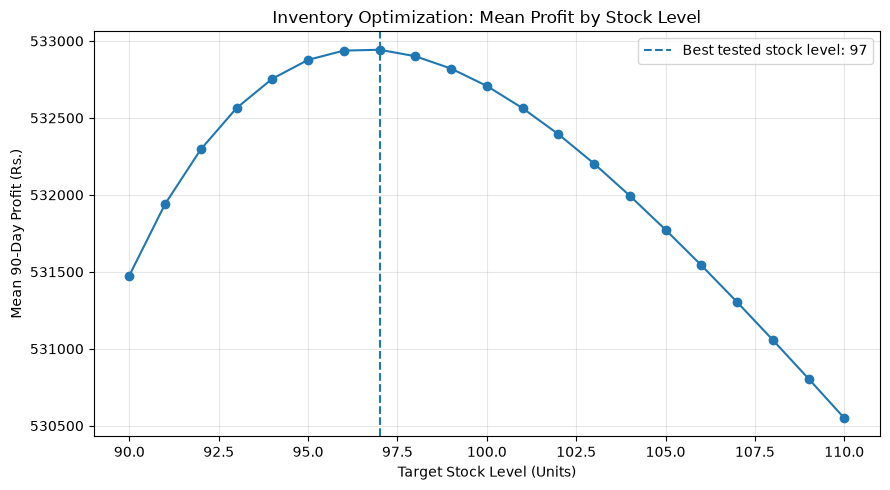

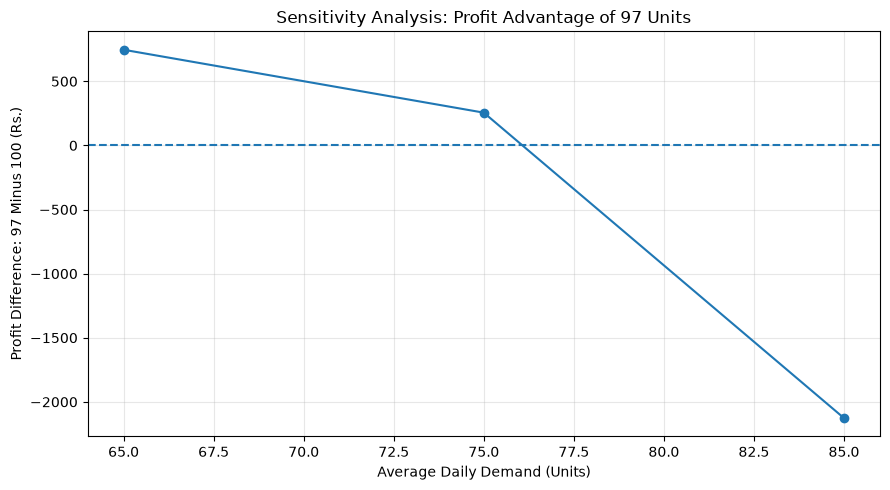

In [75]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

# Chart 1: Refined Inventory Optimization
plt.figure(figsize=(9, 5))

plt.plot(
    refined_df["stock_level"],
    refined_df["mean_profit"],
    marker="o"
)

plt.axvline(
    x=97,
    linestyle="--",
    label="Best tested stock level: 97"
)

plt.xlabel("Target Stock Level (Units)")
plt.ylabel("Mean 90-Day Profit (Rs.)")
plt.title("Inventory Optimization: Mean Profit by Stock Level")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/inventory_optimization.png", dpi=300)
plt.show()


# Chart 2: Demand Sensitivity
plt.figure(figsize=(9, 5))

plt.plot(
    sensitivity_df["mean_daily_demand"],
    sensitivity_df["profit_difference"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Average Daily Demand (Units)")
plt.ylabel("Profit Difference: 97 Minus 100 (Rs.)")
plt.title("Sensitivity Analysis: Profit Advantage of 97 Units")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/demand_sensitivity.png", dpi=300)
plt.show()

### 11.1 Sensitivity Analysis Findings

Sensitivity analysis evaluated inventory policies of 97 and 100 units under three average daily demand assumptions: 65, 75, and 85 units.

At low demand (65 units), the 97-unit policy generated Rs. 746.26 more mean profit over 90 days. At baseline demand (75 units), its advantage decreased to Rs. 255.56.

At high demand (85 units), the 100-unit policy outperformed the 97-unit policy by Rs. 2,126.46. The 97-unit policy also experienced greater unmet demand.

### 11.2 Business Recommendation

The 97-unit policy maximized mean profit among the inventory levels tested under the baseline demand assumptions.

However, the advantage over 100 units was small, while shortages were higher. Sensitivity analysis further showed that the preferred policy changes as average demand increases.

Therefore, businesses should consider both expected profitability and customer service when selecting inventory targets. Stock levels should be reviewed when demand conditions change.

### 11.3 Limitations

- Demand is synthetic rather than based on real transaction records.
- Replenishment is assumed to be immediate.
- Costs, selling prices, and demand variability are held constant during the sensitivity test.
- The reported profit excludes several operational and financing costs.
- The model does not explicitly assign a penalty to unmet demand beyond lost sales.
- The selected policy is optimal only among the evaluated alternatives under the stated assumptions.

In [76]:
from pathlib import Path

print("Optimization chart:", Path("figures/inventory_optimization.png").exists())
print("Sensitivity chart:", Path("figures/demand_sensitivity.png").exists())

Optimization chart: True
Sensitivity chart: True
